# French imbalance-settlement stress: report

ENTSO-E France, 1 January 2021 to 31 December 2024, 30-minute delivery intervals.

## 1. Research question and motivation

### Research question

Using only information available **after the French day-ahead market has cleared but before delivery**, can observable market fundamentals identify the 30-minute intervals of unusually severe imbalance-settlement stress, separately for **short** positions and for **long** positions?

### Motivation

*To be written.*

## 2. Data downloading

All raw data comes from the **ENTSO-E Transparency Platform**, the public data hub of the European grid operators. Getting it took three steps:

1. **Requesting access.** We registered an account on the platform and then emailed ENTSO-E (transparency@entsoe.eu) to ask for access to the RESTful API. Once they approved it, we generated a personal **API key**. The key is kept in a local `.env` file (`ENTSOE_API_KEY`) and is never committed to the repository.
2. **Downloading the raw data.** The scripts in `src/data_downloads_and_manipulation/` use the key with the `entsoe-py` client to pull every series for France from 1 January 2021 to 31 December 2024 (Europe/Paris time) and save each one as a CSV in `Data/Raw/ENSTOE/`.
3. **Fixing the one download that failed.** Every series downloaded in one request except the **activated balancing energy prices**: that request was too large and kept failing or timing out. We therefore downloaded it **one month at a time** (48 files in `balancing_monthly/`) and then combined the months into a single `balancing_energy_prices_fr.csv`.

### The scripts

| Script | What it does |
|---|---|
| `download_entsoe.py` | Connects with the API key and saves one CSV per dataset for 2021-24. If one request fails, the others still run. |
| `download_balancing.py` | Downloads the balancing energy prices month by month. It skips months already saved, so you can rerun it to retry failed months, and it only writes the combined CSV once all 48 months are there. |
| `build_dataset.py` | Turns the raw CSVs into the processed tables. It puts everything on one 30-minute UTC grid, computes $S_{short}$ and $S_{long}$, builds the predictors, sets the q90 thresholds on the training data only, and splits the years into train/validation/test. |

### What the raw data is (France, 2021-24)

| File | Content |
|---|---|
| `day_ahead_prices_fr` | Day-ahead market price $P_{DA}$ (EUR/MWh) |
| `imbalance_prices_fr` | Imbalance settlement prices for short and long positions |
| `imbalance_volumes_fr` | Total system imbalance volume |
| `balancing_energy_prices_fr` | Prices of activated balancing energy (downloaded monthly, see above) |
| `load_forecast_fr` / `actual_load_fr` | Day-ahead demand forecast and actual demand |
| `renewables_forecast_fr` | Day-ahead wind (onshore/offshore) and solar forecasts |
| `generation_actual_fr` | Actual generation by source (nuclear, gas, hydro, wind, solar, …) |
| `scheduled_X_Y` | Day-ahead scheduled commercial exchanges with BE, DE_LU, CH, IT_NORD, ES and GB, both directions |
| `physical_flows_X_Y` | Actual physical cross-border flows with the same neighbours, both directions |

## 3. Data transformation

`build_dataset.py` turns the raw CSVs into the tables used for modelling. The raw files are never changed, so everything can be rebuilt by running the script again.

1. **One time grid.** Every timestamp is read with its timezone and converted to UTC, then placed on a grid of 30-minute delivery intervals for 2021-24. Calendar variables (hour, weekday, season) use Paris time.
2. **Mixed resolutions.** Files switch between hourly, 30-minute and 15-minute data over the years. The script detects each file's spacing from its own timestamps: an hourly value fills both half-hours, two 15-minute power values are averaged, and energy values are summed. A real gap stays blank and is never treated as zero.
3. **Short gaps in forecasts** are filled with the last known forecast for at most 2 hours, and never with future values.
4. **Stress variables.** $S_{short} = P_{short} - P_{DA}$ and $S_{long} = P_{DA} - P_{long}$ (explained below).
5. **Predictors known before delivery.** These are the day-ahead price, load forecast, wind and solar forecasts, and scheduled imports and exports summed over the six neighbours, plus calendar terms. Anything only known after delivery goes into a separate **ex-post table**, which is used to explain events and never as a model input.
6. **Rows kept.** A half-hour is kept when all day-ahead inputs and both stress scores exist: 68,001 half-hours.
7. **Splits and targets.** 2021-22 is used for training, 2023 for validation and 2024 for testing, in time order with no shuffling. The severity cut-offs ($q_{90}$) and the means and standard deviations used for scaling are computed on 2021-22 only, then kept fixed.

### The processed datasets (`Data/Processed/`)


| File | Content |
|---|---|
| `modelling_table.csv` | One row per 30-minute interval: predictors known before delivery, plus $S_{short}$, $S_{long}$ and the train/validation/test split |
| `expost_table.csv` | Realised values (actual load, generation, forecast errors, flows), kept only to explain events and never used as predictors |
| `design_matrix.csv` / `scaler.json` | Scaled predictors and targets for modelling, using means and SDs from the training years only |
| `thresholds.json` | The q90 thresholds for severe stress, set on 2021-22 |
| `missingness_by_year.csv` / `frequency_by_file_year.csv` | Audit tables: share of missing values and timestamp spacing per file and year |

### What $S_{short}$ and $S_{long}$ measure, and why they matter economically

A market participant (a balance-responsible party: a producer, supplier or trader) commits to a position for each delivery interval, mostly through the **day-ahead market**, which clears the day before at price $P_{DA}$. In real time, the participant rarely delivers exactly what it committed: a wind farm produces less than forecast, a factory consumes more than planned. The grid operator (RTE in France) balances the system and then **settles each participant's deviation (imbalance) at an imbalance price** that is only known after delivery.

There are two separate imbalance prices, because being short and being long are settled differently:

* **Short position** (delivered less, or consumed more, than committed). The missing energy is effectively bought back from the system at $P_{short}$. Compared with having bought it on the day-ahead market, the extra cost per MWh is
$$S_{short} = P_{short} - P_{DA}.$$
$S_{short}$ is large when the system as a whole is short: the grid operator has to activate expensive upward balancing (fast gas, imports, demand response), so the imbalance price spikes above day-ahead.

* **Long position** (delivered more, or consumed less, than committed). The surplus is effectively sold back to the system at $P_{long}$. Compared with having sold it on the day-ahead market, the revenue lost per MWh is
$$S_{long} = P_{DA} - P_{long}.$$
$S_{long}$ is large when the system is long: there is too much energy (for example high wind or solar, low demand), the operator activates downward balancing and the imbalance price collapses, sometimes below zero.

The sign of $S_{long}$ is flipped on purpose, so that for **both** positions **$S > 0$ means the outcome was worse than the day-ahead price**, and a larger $S$ means a bigger financial penalty. No absolute values are taken, because they would mix good and bad outcomes.

**Why this matters.** $S$ is the price of being wrong. For a renewable producer it is the cost of a forecast error, for a trader it is the risk of holding an open position into delivery, and for the system it signals how tight balancing was. A model that flags in advance the intervals where this penalty is likely to be **severe** helps a participant decide how much to hedge or re-trade in the intraday market before delivery.

In the data, the two kinds of severe stress almost never happen at the same time (see section 4.4): a system that is very short is not also very long, so they are modelled separately.

In [1]:
from pathlib import Path
import json
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "Data").exists() else Path.cwd().parent
PROCESSED = ROOT / "Data" / "Processed"
table = pd.read_csv(PROCESSED / "modelling_table.csv")
saved = json.loads((PROCESSED / "thresholds.json").read_text())
order = ["train", "validation", "test"]
years = {"train": "2021-22", "validation": "2023", "test": "2024"}
print(f"{len(table):,} clean 30-minute intervals")
print(table["split"].value_counts().loc[order].rename(index=years).to_string())

68,001 clean 30-minute intervals
split
2021-22    34111
2023       16409
2024       17481


## 4. Descriptive analysis

Before any model, this section looks at how the two stress variables are distributed, where the severity cut-offs lie, how often intervals are severe, and how $S_{short}$ and $S_{long}$ relate to each other.

### 4.1 Distribution of $S_{short}$ and $S_{long}$

Before building any model, it helps to look at what the two stress variables look like. The histograms cover the central 98% of intervals (1st to 99th percentile), because the extremes stretch to several thousand EUR/MWh and would squash the picture; the table below gives the full range. The dashed lines mark the upper quartile (q75) and the 90th-percentile cut-off (q90) used to define severe stress, both from 2021-22.

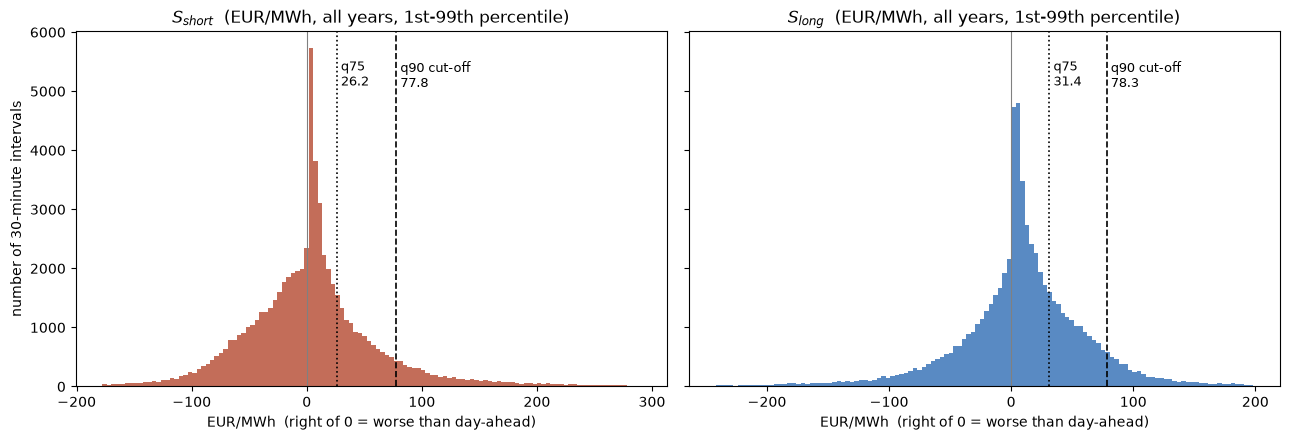

,mean,std,min,1st pct,5th pct,25th pct,median,75th pct,90th pct,95th pct,99th pct,max
S_short,6.20,98.36,-3686.15,-177.51,-88.34,-27.83,3.52,27.76,74.43,118.68,289.64,4117.98
S_long,7.57,94.65,-3552.70,-242.07,-91.50,-14.03,7.83,36.22,71.85,97.65,198.18,4170.79


In [2]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
colors = {"short": "#B5482F", "long": "#2F6DB5"}
for ax, side in zip(axes, ["short", "long"]):
    s = table[f"S_{side}"]
    lo, hi = s.quantile(0.01), s.quantile(0.99)
    ax.hist(s[s.between(lo, hi)], bins=120, range=(lo, hi), color=colors[side], alpha=0.8)
    tr = table.loc[table["split"] == "train", f"S_{side}"]
    for q, ls, lab in [(tr.quantile(0.75), ":", "q75"), (saved[f"q90_{side}"], "--", "q90 cut-off")]:
        ax.axvline(q, color="black", linestyle=ls, linewidth=1.2)
        ax.text(q, ax.get_ylim()[1] * 0.92, f" {lab}\n {q:.1f}", fontsize=9, va="top")
    ax.axvline(0, color="grey", linewidth=0.8)
    ax.set_title(f"$S_{{{side}}}$  (EUR/MWh, all years, 1st-99th percentile)")
    ax.set_xlabel("EUR/MWh  (right of 0 = worse than day-ahead)")
axes[0].set_ylabel("number of 30-minute intervals")
plt.tight_layout()
plt.show()

pct = [0.01, 0.05, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
summary = table[["S_short", "S_long"]].describe(percentiles=pct).T
summary = summary.drop(columns="count").round(2)
ordinal = {"1%": "1st pct", "5%": "5th pct", "25%": "25th pct", "50%": "median", "75%": "75th pct",
           "90%": "90th pct", "95%": "95th pct", "99%": "99th pct"}
summary = summary.rename(columns=ordinal)
summary

### 4.2 The severity thresholds

The thresholds are recomputed here from scratch: the 90th percentile of $S$ over the 2021-22 training half-hours only. They are compared with the values the pipeline saved in `thresholds.json`. For reference the table also shows the 75th percentile (upper quartile), which is **not** the cut-off used.

In [3]:
train = table[table["split"] == "train"]
rows = []
for side in ["short", "long"]:
    s = train[f"S_{side}"]
    q90 = s.quantile(0.90)
    rows.append({"stress": f"S_{side}",
                 "median": round(s.median(), 2),
                 "q75 (upper quartile)": round(s.quantile(0.75), 2),
                 "q90 recomputed (cut-off)": round(q90, 3),
                 "q90 saved by pipeline": round(saved[f"q90_{side}"], 3),
                 "match": abs(q90 - saved[f"q90_{side}"]) < 1e-9,
                 "labels consistent": bool(((table[f"S_{side}"] > q90).astype(int) == table[f"Y_{side}"]).all())})
pd.DataFrame(rows).set_index("stress")

,median,q75 (upper quartile),q90 recomputed (cut-off),q90 saved by pipeline,match,labels consistent
stress,,,,,,
S_short,5.76,26.18,77.83,77.83,True,True
S_long,8.47,31.37,78.35,78.35,True,True


### 4.3 How many intervals are severe ($Y = 1$)?

Counts of $Y = 1$, i.e. intervals where $S$ is above its fixed 2021-22 cut-off. In training the share is 10% by construction; in 2023 and 2024 it can differ, because the cut-off is held fixed rather than re-estimated.

In [4]:
counts = []
for side in ["short", "long"]:
    g = table.groupby("split")[f"Y_{side}"]
    for split in order:
        counts.append({"target": f"Y_{side}", "period": years[split],
                       "intervals": int(g.count()[split]),
                       "Y = 1": int(g.sum()[split]),
                       "share Y = 1": f"{g.mean()[split]:.1%}"})
    counts.append({"target": f"Y_{side}", "period": "all",
                   "intervals": len(table), "Y = 1": int(table[f"Y_{side}"].sum()),
                   "share Y = 1": f"{table[f'Y_{side}'].mean():.1%}"})
display(pd.DataFrame(counts).set_index(["target", "period"]))
both = int(((table["Y_short"] == 1) & (table["Y_long"] == 1)).sum())
print(f"Intervals severe on both sides at once: {both}")

intervals  Y = 1 share Y = 1
target  period                               
Y_short 2021-22      34111   3411       10.0%
        2023         16409   1176        7.2%
        2024         17481   1811       10.4%
        all          68001   6398        9.4%
Y_long  2021-22      34111   3411       10.0%
        2023         16409    868        5.3%
        2024         17481   1406        8.0%
        all          68001   5685        8.4%

Intervals severe on both sides at once: 2


### 4.4 How are $S_{short}$ and $S_{long}$ related?

#### A built-in link

Adding the two definitions gives

$$S_{short} + S_{long} = (P_{short} - P_{DA}) + (P_{DA} - P_{long}) = P_{short} - P_{long},$$

the spread between the two imbalance prices. This spread is never negative and is usually small, so **when one stress is high, the other is pushed down by almost the same amount**. Economically: an interval where the system is very short (expensive to be short) is an interval where being long is rewarded, not penalised. The two variables are therefore close to mirror images, and both can only be severe together when the spread itself is huge.

correlation S_short vs S_long: Pearson -0.988, Spearman -0.956
S_short + S_long equals P_short - P_long on every interval: True
spread P_short - P_long: min 0.00, median 9.70, 90th pct 29.44 EUR/MWh


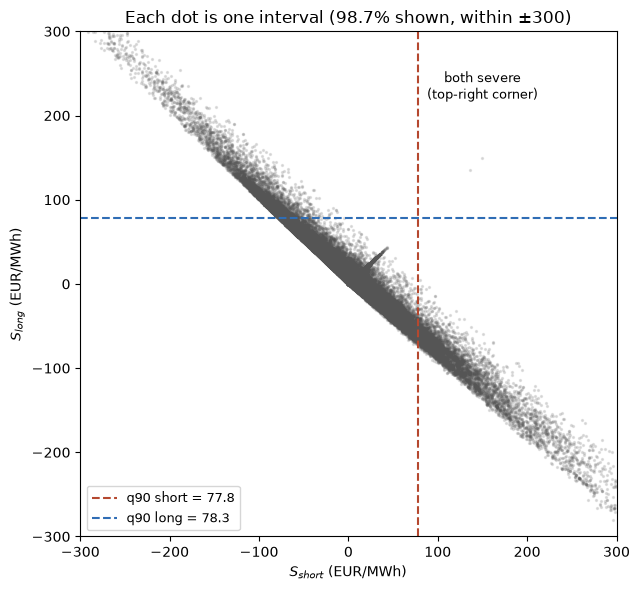

In [5]:
spread = table["price_short"] - table["price_long"]
print(f"correlation S_short vs S_long: Pearson {table['S_short'].corr(table['S_long']):.3f}, "
      f"Spearman {table['S_short'].corr(table['S_long'], method='spearman'):.3f}")
print(f"S_short + S_long equals P_short - P_long on every interval: "
      f"{bool(((table['S_short'] + table['S_long']) - spread).abs().max() < 0.02)}")
print(f"spread P_short - P_long: min {spread.min():.2f}, median {spread.median():.2f}, "
      f"90th pct {spread.quantile(0.9):.2f} EUR/MWh")

fig, ax = plt.subplots(figsize=(6.5, 6))
lim = (-300, 300)
inside = table["S_short"].between(*lim) & table["S_long"].between(*lim)
ax.scatter(table.loc[inside, "S_short"], table.loc[inside, "S_long"], s=2, alpha=0.15, color="#555555")
ax.axvline(saved["q90_short"], color="#B5482F", linestyle="--", label=f"q90 short = {saved['q90_short']:.1f}")
ax.axhline(saved["q90_long"], color="#2F6DB5", linestyle="--", label=f"q90 long = {saved['q90_long']:.1f}")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("$S_{short}$ (EUR/MWh)"); ax.set_ylabel("$S_{long}$ (EUR/MWh)")
ax.set_title(f"Each dot is one interval ({inside.mean():.1%} shown, within ±300)")
ax.text(150, 220, "both severe\n(top-right corner)", ha="center", fontsize=9)
ax.legend(loc="lower left", fontsize=9)
plt.tight_layout()
plt.show()

#### Are both ever severe at the same time?

The table cross-counts $Y_{short}$ and $Y_{long}$ over all 68,001 intervals.

In [6]:
cross = pd.crosstab(table["Y_short"], table["Y_long"], margins=True, margins_name="total")
cross.index = ["Y_short = 0", "Y_short = 1", "total"]
cross.columns = ["Y_long = 0", "Y_long = 1", "total"]
display(cross)
both = table[(table["Y_short"] == 1) & (table["Y_long"] == 1)]
print(f"Intervals with both = 1: {len(both)}, on {both['datetime_paris'].str[:10].nunique()} day(s)")
both[["datetime_paris", "day_ahead_price", "price_short", "price_long", "S_short", "S_long"]].round(2)

,Y_long = 0,Y_long = 1,total
Y_short = 0,55920,5683,61603
Y_short = 1,6396,2,6398
total,62316,5685,68001


Intervals with both = 1: 2, on 1 day(s)


,datetime_paris,day_ahead_price,price_short,price_long,S_short,S_long
21308,2022-04-04 07:30:00+02:00,2712.99,2848.64,2577.34,135.65,135.65
21310,2022-04-04 08:30:00+02:00,2987.78,3137.17,2838.39,149.39,149.39


#### When only one side is severe, how close is the other side to its cut-off?

For every interval where exactly one of $Y_{short}$, $Y_{long}$ is 1, the table measures how far the **other** stress is below its own 90th-percentile cut-off:

$$\text{gap} = q_{90,\text{other}} - S_{\text{other}} \quad (> 0, \text{ in EUR/MWh})$$

A gap of 1 would mean the other side only just missed being severe as well.

In [7]:
rows = []
for hit, other in [("short", "long"), ("long", "short")]:
    only = table[(table[f"Y_{hit}"] == 1) & (table[f"Y_{other}"] == 0)]
    gap = saved[f"q90_{other}"] - only[f"S_{other}"]
    rows.append({"case": f"Y_{hit} = 1, Y_{other} = 0",
                 "intervals": len(only),
                 f"mean gap (EUR/MWh)": round(gap.mean(), 2),
                 "median gap": round(gap.median(), 2),
                 "smallest gap": round(gap.min(), 2),
                 "gaps under 10": int((gap < 10).sum()),
                 "gaps under 1": int((gap < 1).sum())})
pd.DataFrame(rows).set_index("case")

,intervals,mean gap (EUR/MWh),median gap,smallest gap,gaps under 10,gaps under 1
case,,,,,,
"Y_short = 1, Y_long = 0",6396,217.04,173.65,74.09,0,0
"Y_long = 1, Y_short = 0",5683,202.53,172.83,90.37,0,0


On average the other side is about 200 EUR/MWh below its cut-off, and never closer than about 74. This follows from the built-in link above: when one stress is above roughly 78, the other is roughly the spread minus that amount, which is usually well below zero. In other words, a severe interval for one position is almost always a **good** interval for the opposite position, not a near-miss.

## 5. Models

Five models are compared. Each one predicts the two binary targets $Y_{short}$ and $Y_{long}$ (severe means above the 2021-22 90th percentile) with a separate model per target, using only information known before delivery. Models 1 to 4 are fitted on 2021-22, tuned on 2023 and checked once on 2024. Model 5 chooses its settings on rolling folds and is refitted on 2021-2023 before the 2024 check. Their results are in section 6.

### 5.1 Model 1: logistic regression

#### The response variable

The model does not predict the euro amount of $S$. It predicts whether $S$ is **severe**, defined as above its 90th percentile $q_{90}$ (the top 10% of stress), estimated on the 2021-22 training years only and then kept fixed for 2023 and 2024:

$$Y_{short}(t) = \begin{cases} 1 & \text{if } S_{short}(t) > q_{90,short} \\ 0 & \text{otherwise} \end{cases} \qquad\qquad Y_{long}(t) = \begin{cases} 1 & \text{if } S_{long}(t) > q_{90,long} \\ 0 & \text{otherwise} \end{cases}$$

So there are two response variables and two separate models: one for severe short-side stress and one for severe long-side stress. Because $Y$ is 0 or 1, the model is a **logistic regression**, which outputs the probability that $Y = 1$.

#### The explanatory variables

Only information that is **known after the day-ahead auction and before delivery** is used, so the model could actually be run in practice the day before. A half-hour is used when all six day-ahead inputs and both stress scores exist (68,001 half-hours). Nothing measured after delivery selects rows or enters the model, and the code checks it: every feature must be a day-ahead input or a calendar term. 17 variables in total; the continuous ones are standardised (z-scores) using 2021-22 means and standard deviations only.

| Variable | What it is | Why it could matter |
|---|---|---|
| `day_ahead_price` | French day-ahead price, EUR/MWh | the reference price that $S$ is measured against; high prices signal a tight system |
| `load_forecast` | day-ahead forecast of national demand, MW | high expected demand leaves less spare capacity for balancing |
| `wind_onshore_forecast` | day-ahead onshore wind forecast, MW | wind forecasts carry large errors, a main cause of imbalances |
| `solar_forecast` | day-ahead solar forecast, MW | same for solar; also drives midday surpluses |
| `scheduled_imports` | sum of day-ahead schedules from BE, DE_LU, CH, IT_NORD, ES, GB into France, MW | reliance on neighbours |
| `scheduled_exports` | sum of day-ahead schedules from France to those neighbours, MW | how much of French supply is committed abroad |
| `hour_sin`, `hour_cos` | time of day as a smooth cycle | stress follows daily patterns (morning ramp, evening peak) |
| `dow_1` ... `dow_6` | day of week (Monday is the baseline) | weekends and weekdays balance differently |
| `season_spring`, `season_summer`, `season_autumn` | season (winter is the baseline) | seasonal demand and renewable patterns |

**Left out on purpose.**
* `net_scheduled_imports` is exactly imports minus exports, so including it as well would make the coefficients impossible to separate.
* `wind_offshore_forecast` (and `residual_load_forecast`, which uses it) is blank for all of 2021-22, before French offshore farms reported, so a model trained on those years cannot learn from it.
* Anything only known **after** delivery (actual load, actual generation, physical flows, imbalance volumes and the imbalance prices themselves) is excluded, because using it would be looking into the future.

#### How the model works

Each logistic regression adds up the inputs with weights $\beta$ and turns the sum into a probability between 0 and 1:

$$P\big(Y(t) = 1\big) = \sigma\Big(\beta_0 + \sum_{j=1}^{17} \beta_j \, x_j(t)\Big), \qquad \sigma(z) = \frac{1}{1 + e^{-z}}$$

A positive $\beta_j$ means that a higher value of input $j$ makes severe stress more likely. The weights are estimated on 2021-22 only, with an L2 penalty whose strength is chosen on 2023; 2024 is used only for the final check. Code: `src/models/model_1_logistic_regression.py`.

#### Diagram of Model 1

The diagram shows the structure of the model only; it uses no data.

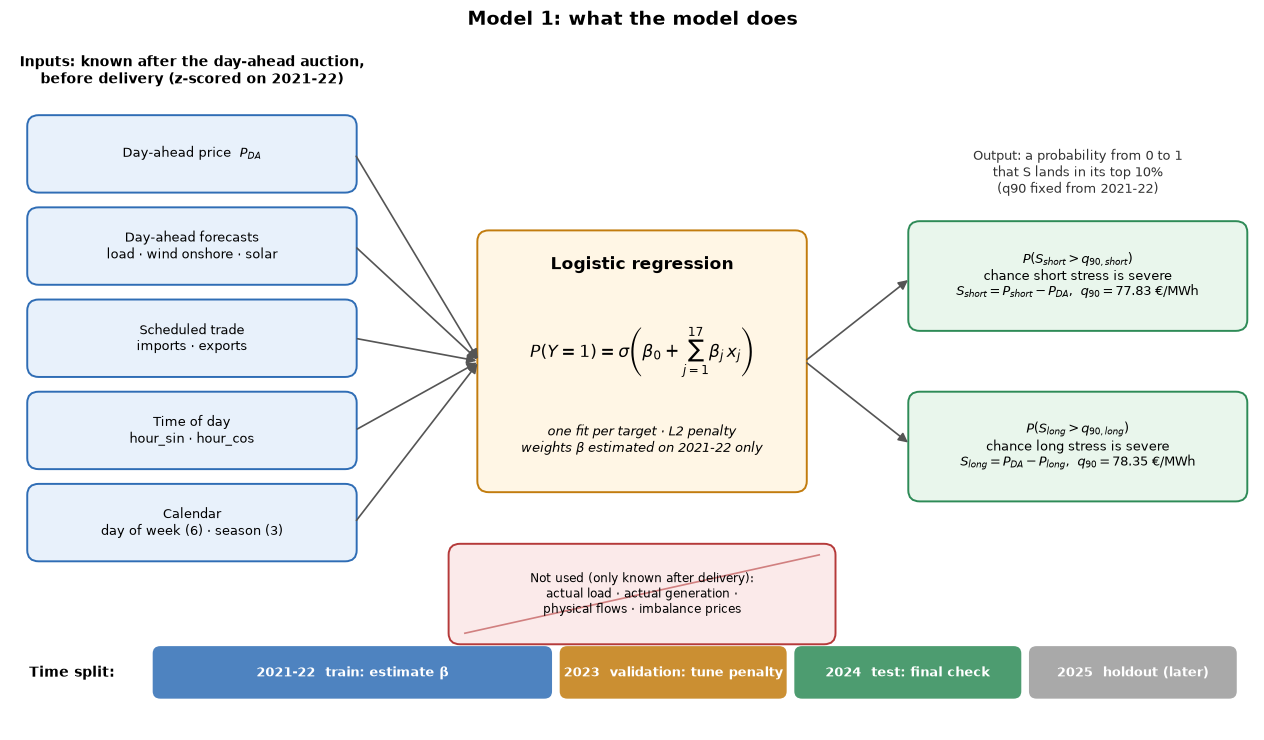

In [8]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(13, 7.5))
ax.set_xlim(0, 13)
ax.set_ylim(0, 7.5)
ax.axis("off")

def box(x, y, w, h, text, face, edge, size=10, weight="normal"):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.12",
                                facecolor=face, edgecolor=edge, linewidth=1.4))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=size, weight=weight)

def arrow(x0, y0, x1, y1, color="#555555"):
    ax.add_patch(FancyArrowPatch((x0, y0), (x1, y1), arrowstyle="-|>", mutation_scale=14,
                                 color=color, linewidth=1.2))

ax.text(1.9, 7.15, "Inputs: known after the day-ahead auction,\nbefore delivery (z-scored on 2021-22)",
        ha="center", va="center", fontsize=10, weight="bold")
inputs = ["Day-ahead price  $P_{DA}$",
          "Day-ahead forecasts\nload · wind onshore · solar",
          "Scheduled trade\nimports · exports",
          "Time of day\nhour_sin · hour_cos",
          "Calendar\nday of week (6) · season (3)"]
ys = [5.85, 4.85, 3.85, 2.85, 1.85]
for y, t in zip(ys, inputs):
    box(0.2, y, 3.4, 0.8, t, "#E8F1FB", "#2F6DB5", size=9.5)

mx, my, mw, mh = 4.9, 2.6, 3.4, 2.8
box(mx, my, mw, mh, "", "#FFF6E5", "#C27C0E")
ax.text(mx + mw / 2, my + mh - 0.4, "Logistic regression", ha="center", fontsize=12, weight="bold")
ax.text(mx + mw / 2, my + mh / 2 + 0.1, r"$P(Y=1)=\sigma\left(\beta_0+\sum_{j=1}^{17}\beta_j\,x_j\right)$",
        ha="center", va="center", fontsize=12.5)
ax.text(mx + mw / 2, my + 0.55, "one fit per target · L2 penalty\nweights β estimated on 2021-22 only",
        ha="center", va="center", fontsize=9, style="italic")
for y in ys:
    arrow(3.6, y + 0.4, mx, my + mh / 2)

q_s, q_l = saved["q90_short"], saved["q90_long"]
box(9.4, 4.35, 3.5, 1.15, r"$P(S_{short} > q_{90,short})$" + "\nchance short stress is severe\n"
    + r"$S_{short}=P_{short}-P_{DA}$,  " + f"$q_{{90}}={q_s:.2f}$ €/MWh", "#E9F6EC", "#2E8B57", size=9)
box(9.4, 2.5, 3.5, 1.15, r"$P(S_{long} > q_{90,long})$" + "\nchance long stress is severe\n"
    + r"$S_{long}=P_{DA}-P_{long}$,  " + f"$q_{{90}}={q_l:.2f}$ €/MWh", "#E9F6EC", "#2E8B57", size=9)
arrow(mx + mw, my + mh / 2, 9.4, 4.9)
arrow(mx + mw, my + mh / 2, 9.4, 3.1)
ax.text(11.15, 6.05, "Output: a probability from 0 to 1\nthat S lands in its top 10%\n(q90 fixed from 2021-22)",
        ha="center", va="center", fontsize=9, color="#333333")

box(4.6, 0.95, 4.0, 1.05, "Not used (only known after delivery):\nactual load · actual generation ·\n"
    "physical flows · imbalance prices", "#FBEAEA", "#B53A3A", size=8.5)
ax.plot([4.75, 8.45], [1.05, 1.9], color="#B53A3A", linewidth=1.2, alpha=0.6)

ax.text(0.2, 0.62, "Time split:", fontsize=10, weight="bold", va="center")
for label, x, w, c in [("2021-22  train: estimate β", 1.5, 4.2, "#2F6DB5"),
                       ("2023  validation: tune penalty", 5.75, 2.4, "#C27C0E"),
                       ("2024  test: final check", 8.2, 2.4, "#2E8B57"),
                       ("2025  holdout (later)", 10.65, 2.2, "#9A9A9A")]:
    ax.add_patch(FancyBboxPatch((x, 0.35), w - 0.05, 0.55, boxstyle="round,pad=0.01,rounding_size=0.08",
                                facecolor=c, edgecolor="none", alpha=0.85))
    ax.text(x + (w - 0.05) / 2, 0.62, label, ha="center", va="center", fontsize=9, color="white",
            weight="bold")

ax.set_title("Model 1: what the model does", fontsize=14, weight="bold", pad=10)
plt.tight_layout()
plt.show()

### 5.2 Model 2: logistic regression with market regimes

#### The response variable

The same two responses as Model 1, $Y_{short}$ and $Y_{long}$ (severe means above the 2021-22 90th percentile), each with its own logistic regression.

#### The explanatory variables

The 17 variables of Model 1, plus **two regime probabilities** from a hidden Markov model (HMM). That makes 19 variables.

**The HMM.** An HMM assumes the market is always in one of a small number of hidden states (here 3), that each state produces typical values of the day-ahead inputs, and that the market tends to stay in a state from one half-hour to the next. It is fitted on 2021-22 only, on the six day-ahead inputs (price, load forecast, wind and solar forecasts, scheduled imports and exports), each standardised with 2021-22 means and standard deviations. Each state has its own mean and variance for every input, with no correlation between inputs inside a state. Three random starts are tried and the one with the highest training likelihood is kept. Gaps in the data are not bridged: each unbroken run of training data is a separate sequence.

**Filtered probabilities only.** For each half-hour the HMM gives the probability of being in each state given the data **up to and including that half-hour**. The more common smoothed version also uses later data and would leak the future, so it is not used. When an input is missing the probability moves forward in time with the transition matrix and no new evidence. States are ordered by their mean day-ahead price; the two probabilities of the higher-priced states enter the regression (the third follows from them).

#### How the model works

Exactly as in Model 1, with two more inputs:

$$P\big(Y(t) = 1\big) = \sigma\Big(\beta_0 + \sum_{j=1}^{17} \beta_j \, x_j(t) + \beta_{18}\,\pi_2(t) + \beta_{19}\,\pi_3(t)\Big)$$

where $\pi_k(t)$ is the filtered probability of regime $k$. The HMM and the weights are estimated on 2021-22 only, the penalty on 2023, and 2024 is the final check. Code: `src/models/model_2_logistic_hmm.py`.

#### What the three states look like

Mean of each input in each state, in original units, and how long the market stays in a state:

In [9]:

regimes = json.loads((ROOT / "results" / "model_2" / "regimes.json").read_text())
means = pd.DataFrame(regimes["emission_means"], columns=regimes["inputs"],
                     index=["state 1 (lowest price)", "state 2", "state 3 (highest price)"])
stay = pd.Series([regimes["transition_matrix"][k][k] for k in range(3)], index=means.index)
means["P(stay next half-hour)"] = stay
means["expected run (half-hours)"] = 1 / (1 - stay)
print(f"fitted on {regimes['training_observations']:,} half-hours in {regimes['training_sequences']} unbroken runs")
means.round(2)


fitted on 34,686 half-hours in 10 unbroken runs


,day_ahead_price,load_forecast,wind_onshore_forecast,solar_forecast,scheduled_imports,scheduled_exports,P(stay next half-hour),expected run (half-hours)
state 1 (lowest price),100.31,51134.37,4652.82,3419.33,2879.18,9784.71,0.95,21.57
state 2,182.35,51146.58,4330.52,0.08,5782.07,7190.50,0.96,23.71
state 3 (highest price),305.44,54640.92,2952.65,4057.63,7677.26,4133.04,0.95,20.50


State 3 is the stressed market: the highest price and load forecast, the highest scheduled imports, and the lowest exports and wind. State 1 is the calmest, with the lowest price and imports and the highest exports. State 2 has a solar forecast of about zero, so it mostly marks night-time, which the hour-of-day variables of Model 1 already describe. Each state typically lasts about 10 to 12 hours.

The regime probabilities add little to the logistic regression (see section 6).

#### Diagram of Model 2

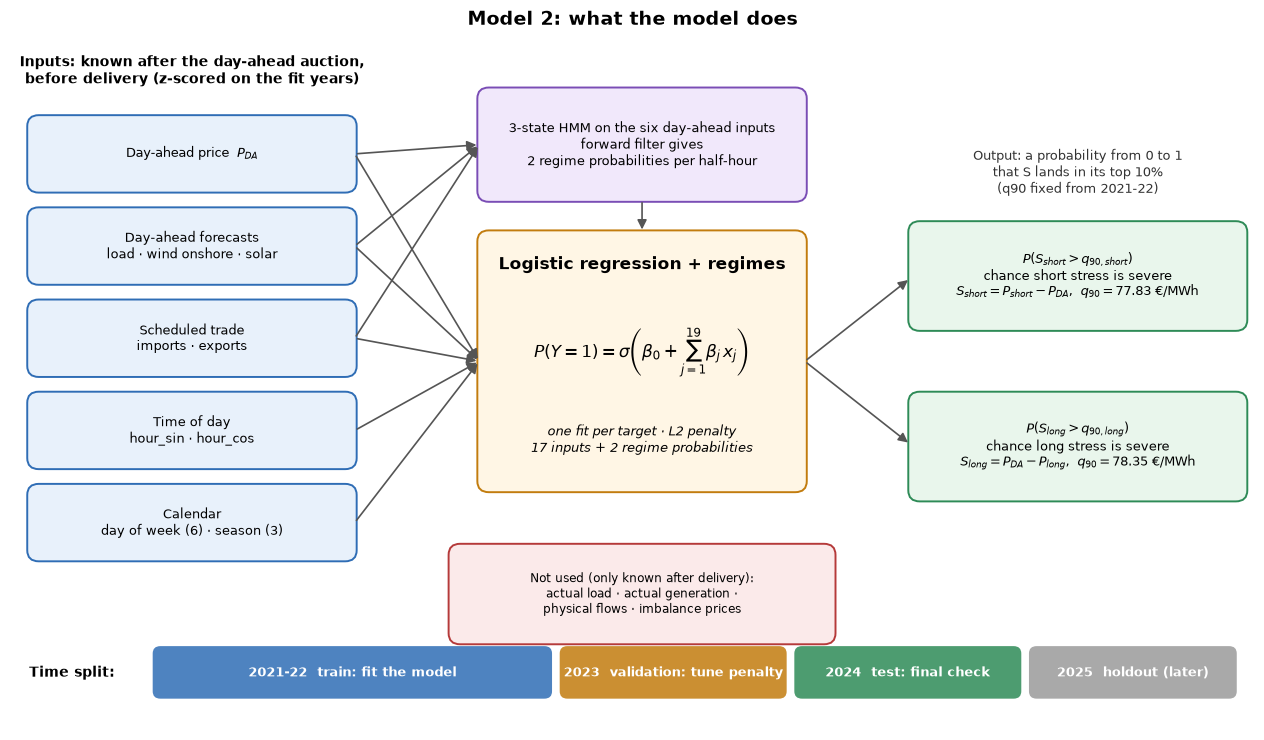

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

HMM_BOX = ("3-state HMM on the six day-ahead inputs\nforward filter gives\n"
           "2 regime probabilities per half-hour", "#F1E8FB", "#7A4DB5")
BASE_INPUTS = ["Day-ahead price  $P_{DA}$", "Day-ahead forecasts\nload · wind onshore · solar",
               "Scheduled trade\nimports · exports", "Time of day\nhour_sin · hour_cos",
               "Calendar\nday of week (6) · season (3)"]

def model_diagram(title, model_title, formula, note, side_box=None, tune="tune the settings",
                  inputs=None, split=None):
    """Same layout as the Model 1 diagram. `side_box` adds a step above the model (the HMM)."""
    inputs = inputs or BASE_INPUTS
    fig, ax = plt.subplots(figsize=(13, 7.5))
    ax.set_xlim(0, 13); ax.set_ylim(0, 7.5); ax.axis("off")

    def box(x, y, w, h, text, face, edge, size=10, weight="normal"):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.12",
                                    facecolor=face, edgecolor=edge, linewidth=1.4))
        ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=size, weight=weight)

    def arrow(x0, y0, x1, y1):
        ax.add_patch(FancyArrowPatch((x0, y0), (x1, y1), arrowstyle="-|>", mutation_scale=14,
                                     color="#555555", linewidth=1.2))

    ax.text(1.9, 7.15, "Inputs: known after the day-ahead auction,\nbefore delivery (z-scored on the fit years)",
            ha="center", va="center", fontsize=10, weight="bold")
    height = 0.8 if len(inputs) <= 5 else 0.7
    ys = list(np.linspace(5.85, 1.85, len(inputs)))
    for y, t in zip(ys, inputs):
        box(0.2, y, 3.4, height, t, "#E8F1FB", "#2F6DB5", size=9)

    mx, my, mw, mh = 4.9, 2.6, 3.4, 2.8
    box(mx, my, mw, mh, "", "#FFF6E5", "#C27C0E")
    ax.text(mx + mw / 2, my + mh - 0.4, model_title, ha="center", fontsize=12, weight="bold")
    ax.text(mx + mw / 2, my + mh / 2 + 0.1, formula, ha="center", va="center", fontsize=12)
    ax.text(mx + mw / 2, my + 0.55, note, ha="center", va="center", fontsize=9, style="italic")
    for y in ys:
        arrow(3.6, y + height / 2, mx, my + mh / 2)
    if side_box:
        text, face, edge = side_box
        box(mx, 5.75, mw, 1.2, text, face, edge, size=9)
        for y in ys[:3]:
            arrow(3.6, y + height / 2, mx, 6.35)
        arrow(mx + mw / 2, 5.75, mx + mw / 2, my + mh)

    q_s, q_l = saved["q90_short"], saved["q90_long"]
    box(9.4, 4.35, 3.5, 1.15, r"$P(S_{short} > q_{90,short})$" + "\nchance short stress is severe\n"
        + r"$S_{short}=P_{short}-P_{DA}$,  " + f"$q_{{90}}={q_s:.2f}$ €/MWh", "#E9F6EC", "#2E8B57", size=9)
    box(9.4, 2.5, 3.5, 1.15, r"$P(S_{long} > q_{90,long})$" + "\nchance long stress is severe\n"
        + r"$S_{long}=P_{DA}-P_{long}$,  " + f"$q_{{90}}={q_l:.2f}$ €/MWh", "#E9F6EC", "#2E8B57", size=9)
    arrow(mx + mw, my + mh / 2, 9.4, 4.9)
    arrow(mx + mw, my + mh / 2, 9.4, 3.1)
    ax.text(11.15, 6.05, "Output: a probability from 0 to 1\nthat S lands in its top 10%\n(q90 fixed from 2021-22)",
            ha="center", va="center", fontsize=9, color="#333333")
    box(4.6, 0.95, 4.0, 1.05, "Not used (only known after delivery):\nactual load · actual generation ·\n"
        "physical flows · imbalance prices", "#FBEAEA", "#B53A3A", size=8.5)
    ax.text(0.2, 0.62, "Time split:", fontsize=10, weight="bold", va="center")
    split = split or [("2021-22  train: fit the model", 1.5, 4.2, "#2F6DB5"),
                      (f"2023  validation: {tune}", 5.75, 2.4, "#C27C0E"),
                      ("2024  test: final check", 8.2, 2.4, "#2E8B57"),
                      ("2025  holdout (later)", 10.65, 2.2, "#9A9A9A")]
    for label, x, w, c in split:
        ax.add_patch(FancyBboxPatch((x, 0.35), w - 0.05, 0.55, boxstyle="round,pad=0.01,rounding_size=0.08",
                                    facecolor=c, edgecolor="none", alpha=0.85))
        ax.text(x + (w - 0.05) / 2, 0.62, label, ha="center", va="center", fontsize=9, color="white", weight="bold")
    ax.set_title(title, fontsize=14, weight="bold", pad=10)
    plt.tight_layout()
    plt.show()

model_diagram("Model 2: what the model does", "Logistic regression + regimes",
              r"$P(Y=1)=\sigma\left(\beta_0+\sum_{j=1}^{19}\beta_j\,x_j\right)$",
              "one fit per target · L2 penalty\n17 inputs + 2 regime probabilities",
              side_box=HMM_BOX, tune="tune penalty")


### 5.3 Model 3: gradient-boosted trees (XGBoost)

#### The response variable

Again $Y_{short}$ and $Y_{long}$, one model each.

#### The explanatory variables

The same 17 variables as Model 1, with the same standardisation (trees do not need it, but keeping the inputs identical makes the comparison with Model 1 fair).

#### How the model works

A logistic regression adds the inputs up in a straight line, so every input pushes the probability the same way at every level of the others. **Boosted trees** can capture interactions and thresholds, for example "a high price matters only when imports are also high". The model is a sum of many small decision trees built one after another, each one fitted to the mistakes of the trees before it:

$$P\big(Y(t) = 1\big) = \sigma\Big(\sum_{m=1}^{M} \eta \, f_m\big(x(t)\big)\Big)$$

where each $f_m$ is a small tree and the learning rate $\eta$ shrinks every tree's contribution so that no single tree dominates. Three settings control how flexible the model is: the depth of each tree (2, 3 or 5), the learning rate (0.03 or 0.1) and the number of trees (100 or 300). All 12 combinations are fitted on 2021-22 and the one with the best average precision on 2023 is kept, separately for each target. 2024 is used only for the final check. Code: `src/models/model_3_xgboost.py`.

#### Diagram of Model 3

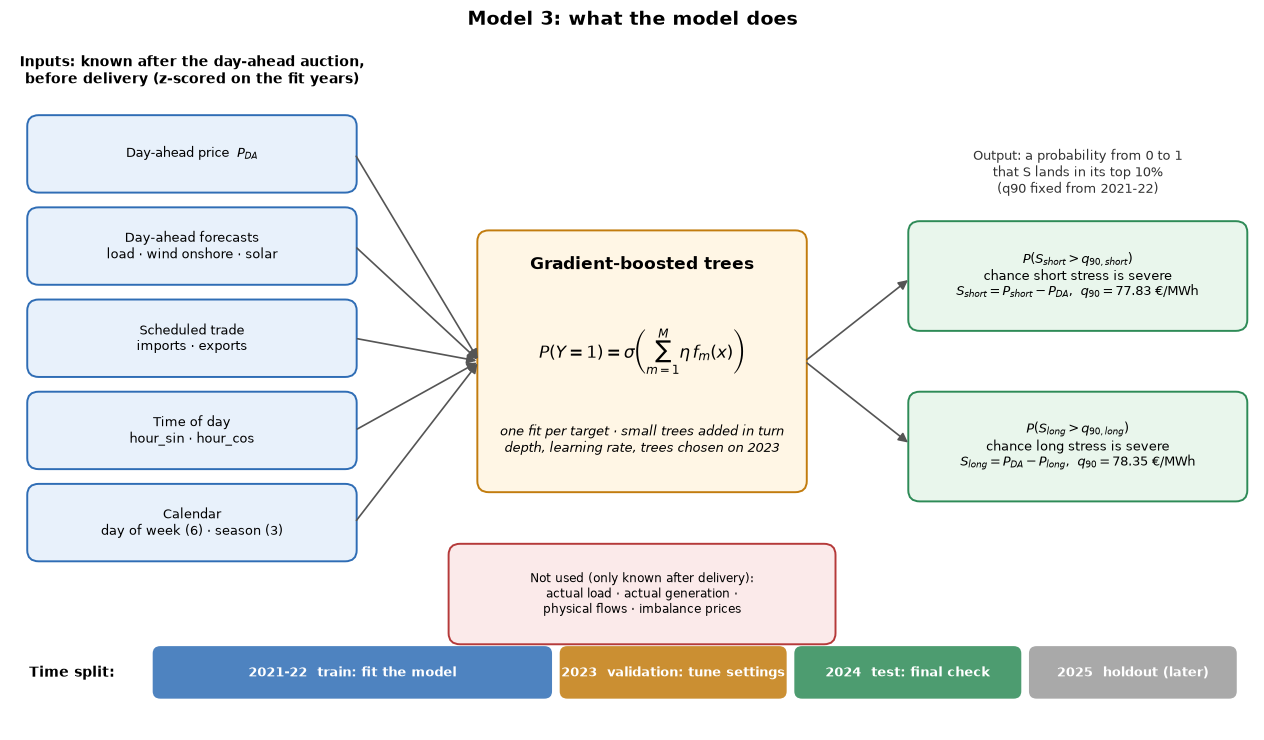

In [11]:

model_diagram("Model 3: what the model does", "Gradient-boosted trees",
              r"$P(Y=1)=\sigma\left(\sum_{m=1}^{M}\eta\,f_m(x)\right)$",
              "one fit per target · small trees added in turn\ndepth, learning rate, trees chosen on 2023",
              tune="tune settings")


### 5.4 Model 4: gradient-boosted trees with market regimes

#### The response variable

Again $Y_{short}$ and $Y_{long}$, one model each.

#### The explanatory variables

The 17 variables of Model 1 plus the two regime probabilities of Model 2 (same HMM, same filtered probabilities), so 19 variables.

#### How the model works

Exactly Model 3 with two more inputs, and the same grid of 12 settings chosen on 2023. Because only the inputs differ from Model 3, any difference between the two comes from the regime probabilities. Code: `src/models/model_4_xgboost_hmm.py`.

#### Diagram of Model 4

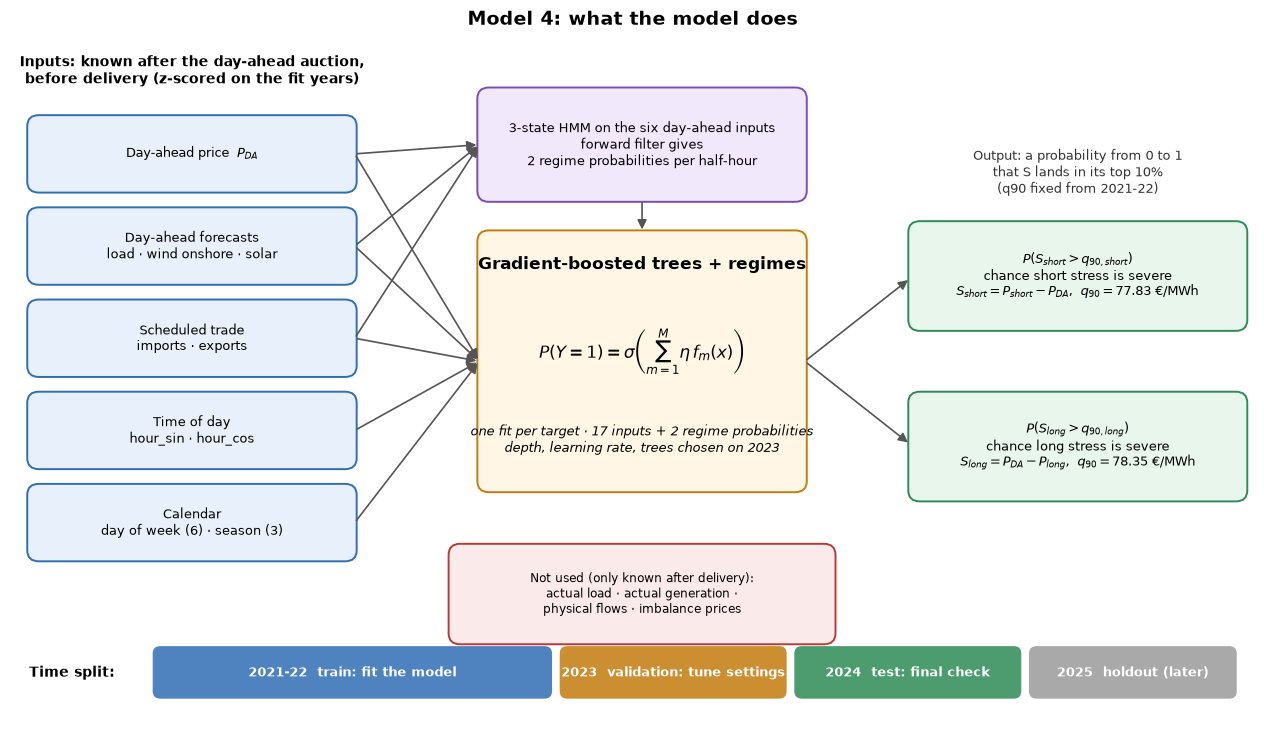

In [12]:

model_diagram("Model 4: what the model does", "Gradient-boosted trees + regimes",
              r"$P(Y=1)=\sigma\left(\sum_{m=1}^{M}\eta\,f_m(x)\right)$",
              "one fit per target · 17 inputs + 2 regime probabilities\ndepth, learning rate, trees chosen on 2023",
              side_box=HMM_BOX, tune="tune settings")


### 5.5 Model 5: rolling features, logistic regression and boosted trees, calibrated

#### The response variable

Again $Y_{short}$ and $Y_{long}$, one model each.

#### The explanatory variables

The 17 variables of Model 1 plus 7 new ones, 24 in total. All 7 are computed from information available before the delivery day.

| Variable | What it is | Why it could matter |
|---|---|---|
| `price_dev7` | day-ahead price minus the average day-ahead price of the previous 7 days | tells whether the price is high compared with the current price level, not only in absolute terms |
| `price_dev30` | the same, over the previous 30 days | the same, with a longer memory |
| `residual_load` | load forecast minus the wind and solar forecasts, MW | the demand that other plants and imports still have to cover |
| `ysr_short`, `ysr_long` | share of severe half-hours (Y = 1) at the same time of day over the 7 days D-8 to D-2 | recent stress at this hour; stress comes in clusters |
| `ydr_short`, `ydr_long` | share of severe half-hours over all of the 7 days D-8 to D-2 | recent stress in general |

For delivery day D the stress history stops at day D-2. Day D-1 is not complete when the auction for day D clears, so it is not used. The first week of 2021 has no history; the missing values are replaced by the training mean for the logistic regression and handled by the trees directly. The new variables are standardised with the means and standard deviations of the years used to fit the model.

#### How the model works

Three candidates are built for each target, all on the 24 variables:

1. a **logistic regression** with an L2 penalty, as in Model 1;
2. **boosted trees**, as in Model 3, but with shallower trees (depth 1 or 2), a minimum weight per leaf, and each tree seeing a random 80% of the rows and variables;
3. the **average** of the probabilities of the two.

**Choosing the settings.** The settings are chosen with two rolling folds: fit on 2021 and score 2022, then fit on 2021-22 and score 2023. For each candidate the settings with the best average precision over the two folds are kept, and the candidate with the best average over the two folds is selected, separately for each target.

**Final model.** The selected candidate is refitted on 2021-2023 and scored once on 2024. Its probabilities are then calibrated with Platt scaling: a logistic regression of the outcome on the logit of the score, fitted on the out-of-fold predictions of the two folds. Calibration is a monotone change, so it improves the probabilities (Brier score and log loss) without changing the ranking (ROC-AUC and average precision).

Code: `src/models/model_5_rolling.py`.

The candidate that won on each target, with its average precision averaged over the two folds:

In [13]:

selected = json.loads((ROOT / "results" / "model_5" / "selected.json").read_text())
names = {"logit": "logistic regression", "xgb": "boosted trees", "blend": "average of the two"}
pd.DataFrame({target: {"selected": names[v["kind"]],
                       **{f"mean AP, {names[k]}": round(a, 4) for k, a in v["cv_ap"].items()}}
              for target, v in selected.items()}).T


,selected,"mean AP, logistic regression","mean AP, boosted trees","mean AP, average of the two"
Y_short,logistic regression,0.1616,0.1457,0.1598
Y_long,average of the two,0.2077,0.1999,0.2078


On the short side the logistic regression wins narrowly over the average (0.1616 against 0.1598) and clearly over the boosted trees (0.1457). On the long side the average narrowly beats the logistic regression alone (0.2078 against 0.2077), so that choice is close to a tie. The selected logistic penalty on the long side is very strong (C = 0.0001).

#### Diagram of Model 5

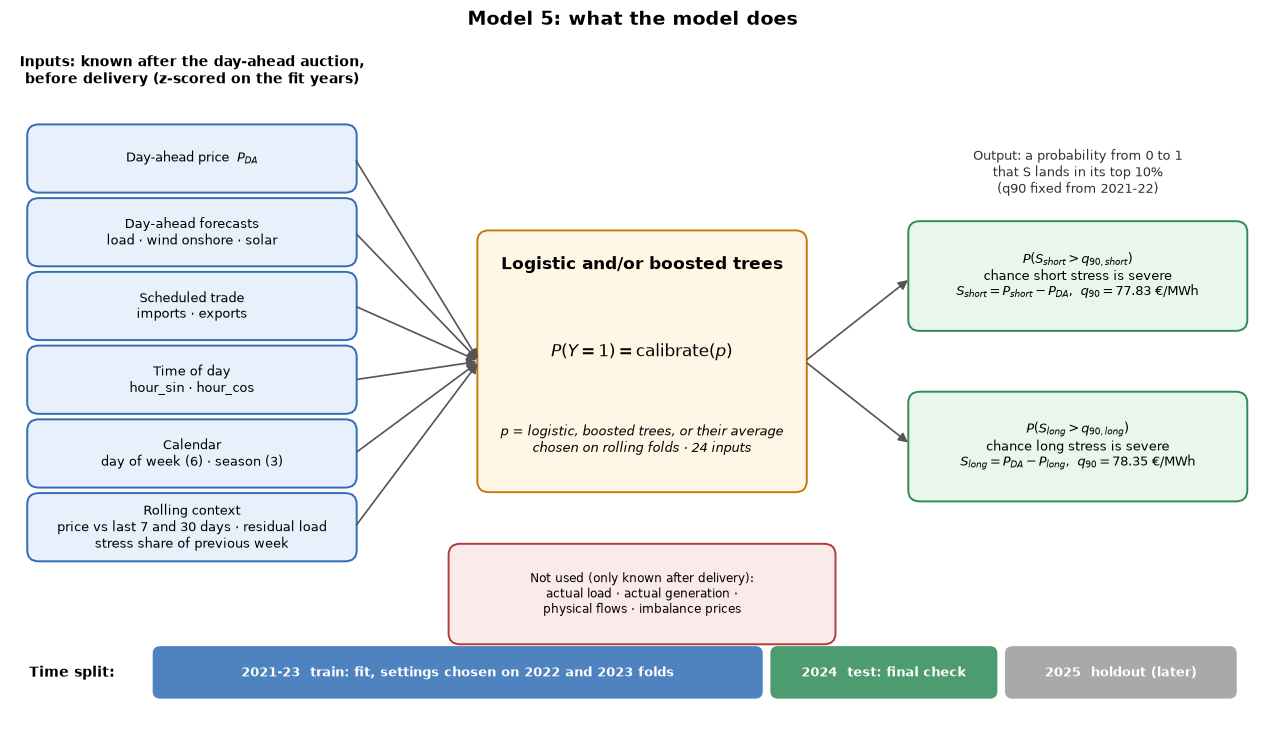

In [14]:

model_diagram("Model 5: what the model does", "Logistic and/or boosted trees",
              r"$P(Y=1)=\mathrm{calibrate}(p)$",
              "p = logistic, boosted trees, or their average\nchosen on rolling folds · 24 inputs",
              inputs=BASE_INPUTS + ["Rolling context\nprice vs last 7 and 30 days · residual load\nstress share of previous week"],
              split=[("2021-23  train: fit, settings chosen on 2022 and 2023 folds", 1.5, 6.4, "#2F6DB5"),
                     ("2024  test: final check", 7.95, 2.4, "#2E8B57"),
                     ("2025  holdout (later)", 10.4, 2.45, "#9A9A9A")])


## 6. Results and limitations

### 6.1 Model 1 results

Metrics for each target on each period. `roc_auc` and `pr_auc` measure how well the model ranks severe intervals above ordinary ones (0.5 and the base rate are what a model with no skill would get). `precision_top10` is the share of severe intervals among the 10% of intervals the model scores highest. `brier` and `log_loss` score the probabilities themselves; the `_constant` columns are a forecast that always says the 2021-22 event rate (10%), which a useful model has to beat.

In [15]:

SETTINGS = ["kind", "C", "max_depth", "learning_rate", "n_estimators", "min_child_weight"]
SHOWN = ["base_rate", "roc_auc", "pr_auc", "precision_top10", "brier", "brier_constant",
         "log_loss", "log_loss_constant"]

def results_table(model):
    """Metrics of one model by target and split, plus the settings chosen on 2023."""
    m = pd.read_csv(ROOT / "results" / f"model_{model}" / "metrics.csv")
    chosen = m[m["split"] == "validation"].set_index("target")[[c for c in SETTINGS if c in m]]
    print("settings used:")
    for target, row in chosen.iterrows():
        print(f"  {target}: " + ", ".join(f"{k} = {v:g}" if not isinstance(v, str) else f"{k} = {v}"
                                          for k, v in row.dropna().items()))
    return m.set_index(["target", "split"])[SHOWN].round(4)

results_table(1)

settings used:
  Y_short: C = 100
  Y_long: C = 0.001


base_rate  roc_auc  pr_auc  precision_top10   brier  \
target  split                                                             
Y_short train          0.1000   0.7151  0.2063           0.2507  0.0851   
        validation     0.0717   0.6041  0.1008           0.1237  0.0663   
        test           0.1036   0.5302  0.1129           0.1167  0.0980   
Y_long  train          0.1000   0.7985  0.2988           0.3483  0.0799   
        validation     0.0529   0.5948  0.0766           0.0884  0.0499   
        test           0.0804   0.5829  0.1022           0.1098  0.0756   

                    brier_constant  log_loss  log_loss_constant  
target  split                                                    
Y_short train               0.0900    0.2989             0.3251  
        validation          0.0673    0.2570             0.2628  
        test                0.0929    0.3955             0.3330  
Y_long  train               0.0900    0.2759             0.3251  
        validation          0.0523    0.2048             0.2216  
        test                0.0743    0.2975             0.2821

### 6.2 Model 2 results

In [16]:
results_table(2)

settings used:
  Y_short: C = 100
  Y_long: C = 0.001


base_rate  roc_auc  pr_auc  precision_top10   brier  \
target  split                                                             
Y_short train          0.1000   0.7169  0.2081           0.2536  0.0850   
        validation     0.0717   0.6070  0.1018           0.1261  0.0663   
        test           0.1036   0.5357  0.1147           0.1190  0.0979   
Y_long  train          0.1000   0.7989  0.2992           0.3509  0.0798   
        validation     0.0529   0.5912  0.0775           0.0865  0.0499   
        test           0.0804   0.5847  0.1032           0.1018  0.0756   

                    brier_constant  log_loss  log_loss_constant  
target  split                                                    
Y_short train               0.0900    0.2984             0.3251  
        validation          0.0673    0.2566             0.2628  
        test                0.0929    0.3947             0.3330  
Y_long  train               0.0900    0.2757             0.3251  
        validation          0.0523    0.2050             0.2216  
        test                0.0743    0.2978             0.2821

### 6.3 Model 3 results

In [17]:
results_table(3)

settings used:
  Y_short: max_depth = 2, learning_rate = 0.03, n_estimators = 300
  Y_long: max_depth = 2, learning_rate = 0.03, n_estimators = 100


base_rate  roc_auc  pr_auc  precision_top10   brier  \
target  split                                                             
Y_short train          0.1000   0.7575  0.2735           0.3026  0.0825   
        validation     0.0717   0.6005  0.0950           0.1024  0.0664   
        test           0.1036   0.5542  0.1228           0.1419  0.0969   
Y_long  train          0.1000   0.8171  0.3319           0.3600  0.0780   
        validation     0.0529   0.6880  0.1019           0.1048  0.0492   
        test           0.0804   0.6437  0.1397           0.1590  0.0759   

                    brier_constant  log_loss  log_loss_constant  
target  split                                                    
Y_short train               0.0900    0.2868             0.3251  
        validation          0.0673    0.2565             0.2628  
        test                0.0929    0.3772             0.3330  
Y_long  train               0.0900    0.2643             0.3251  
        validation          0.0523    0.1979             0.2216  
        test                0.0743    0.3111             0.2821

For both targets the chosen model uses trees of depth 2 and a learning rate of 0.03, the smallest values in the grid. Deeper trees did worse on 2023: the best depth-5 model reaches an average precision of 0.092 (short) and 0.078 (long), against 0.095 and 0.102 for the chosen depth-2 model. The table below shows which inputs the trees use most (the share of the total gain in fit that each input provides).

In [18]:

importance = pd.read_csv(ROOT / "results" / "model_3" / "feature_importance.csv", index_col="feature")
top = pd.concat({t: importance[t].sort_values(ascending=False).head(6).round(3).reset_index().rename(
        columns={"feature": "input", t: "importance"}) for t in ["Y_short", "Y_long"]}, axis=1)
top


Y_short                              Y_long           
                     input importance                    input importance
0        day_ahead_price_z      0.202        day_ahead_price_z      0.380
1      scheduled_exports_z      0.154          load_forecast_z      0.198
2      scheduled_imports_z      0.146         solar_forecast_z      0.100
3                    dow_6      0.070      scheduled_imports_z      0.079
4  wind_onshore_forecast_z      0.058  wind_onshore_forecast_z      0.063
5                    dow_3      0.058      scheduled_exports_z      0.063

For severe long-side stress the day-ahead price is the most used input by a wide margin, followed by the load forecast and the solar forecast. For severe short-side stress the price comes first, followed by the scheduled exports and imports.

### 6.4 Model 4 results

In [19]:
results_table(4)

settings used:
  Y_short: max_depth = 3, learning_rate = 0.03, n_estimators = 100
  Y_long: max_depth = 2, learning_rate = 0.03, n_estimators = 100


base_rate  roc_auc  pr_auc  precision_top10   brier  \
target  split                                                             
Y_short train          0.1000   0.7583  0.2712           0.3034  0.0829   
        validation     0.0717   0.6005  0.0965           0.1042  0.0662   
        test           0.1036   0.5646  0.1284           0.1573  0.0961   
Y_long  train          0.1000   0.8171  0.3319           0.3600  0.0780   
        validation     0.0529   0.6880  0.1019           0.1048  0.0492   
        test           0.0804   0.6437  0.1397           0.1590  0.0759   

                    brier_constant  log_loss  log_loss_constant  
target  split                                                    
Y_short train               0.0900    0.2883             0.3251  
        validation          0.0673    0.2552             0.2628  
        test                0.0929    0.3637             0.3330  
Y_long  train               0.0900    0.2643             0.3251  
        validation          0.0523    0.1979             0.2216  
        test                0.0743    0.3111             0.2821

The selected settings are the same as in Model 3. For the long side the trees never use the regime probabilities, so Model 4 gives exactly the same predictions as Model 3. For the short side they are used a little (about 10% of the total gain together), and the test results move slightly.

### 6.5 Model 5 results

In the table, `train` and `validation` come from the model fitted on 2021-22 and `test` from the final model, fitted on 2021-2023 and calibrated.

In [20]:
results_table(5)

settings used:
  Y_short: kind = logit, C = 0.01
  Y_long: kind = blend, C = 0.0001, max_depth = 1, learning_rate = 0.02, n_estimators = 400, min_child_weight = 10


base_rate  roc_auc  pr_auc  precision_top10   brier  \
target  split                                                             
Y_short train          0.1000   0.7286  0.2276           0.2674  0.0841   
        validation     0.0717   0.6226  0.1104           0.1341  0.0659   
        test           0.1036   0.5719  0.1330           0.1568  0.0932   
Y_long  train          0.1000   0.8211  0.3181           0.3653  0.0785   
        validation     0.0529   0.6907  0.1397           0.1688  0.0492   
        test           0.0804   0.6938  0.1718           0.2054  0.0719   

                    brier_constant  log_loss  log_loss_constant  
target  split                                                    
Y_short train               0.0900    0.2948             0.3251  
        validation          0.0673    0.2537             0.2628  
        test                0.0929    0.3362             0.3330  
Y_long  train               0.0900    0.2686             0.3251  
        validation          0.0523    0.1988             0.2216  
        test                0.0743    0.2681             0.2821

### 6.6 Comparison of Models 1 to 5

Ranking quality by model, target and period. The `base rate` is the share of severe intervals in that period, so it is the average precision of a model with no skill; 0.5 is the ROC-AUC of a model with no skill. Models 1 to 4 are fitted on 2021-22, and Model 5 on 2021-2023, so its test result is not strictly like for like.

In [21]:

rows = []
for model, name in [(1, "1 logistic"), (2, "2 logistic + regimes"), (3, "3 boosted trees"), (4, "4 boosted trees + regimes"), (5, "5 rolling features + calibration")]:
    m = pd.read_csv(ROOT / "results" / f"model_{model}" / "metrics.csv")
    for _, r in m.iterrows():
        rows.append({"model": name, "target": r["target"], "split": r["split"], "base_rate": r["base_rate"],
                     "roc_auc": r["roc_auc"], "pr_auc": r["pr_auc"],
                     "brier_gain": r["brier_constant"] - r["brier"], "logloss_gain": r["log_loss_constant"] - r["log_loss"]})
comparison = pd.DataFrame(rows)
summary = comparison.pivot_table(index=["target", "model"], columns="split", values=["roc_auc", "pr_auc"])
summary = summary.reindex(columns=["train", "validation", "test"], level=1).round(3)
summary


pr_auc                   roc_auc  \
split                                     train validation   test   train   
target  model                                                               
Y_long  1 logistic                        0.299      0.077  0.102   0.798   
        2 logistic + regimes              0.299      0.077  0.103   0.799   
        3 boosted trees                   0.332      0.102  0.140   0.817   
        4 boosted trees + regimes         0.332      0.102  0.140   0.817   
        5 rolling features + calibration  0.318      0.140  0.172   0.821   
Y_short 1 logistic                        0.206      0.101  0.113   0.715   
        2 logistic + regimes              0.208      0.102  0.115   0.717   
        3 boosted trees                   0.273      0.095  0.123   0.758   
        4 boosted trees + regimes         0.271      0.096  0.128   0.758   
        5 rolling features + calibration  0.228      0.110  0.133   0.729   

                                                            
split                                    validation   test  
target  model                                               
Y_long  1 logistic                            0.595  0.583  
        2 logistic + regimes                  0.591  0.585  
        3 boosted trees                       0.688  0.644  
        4 boosted trees + regimes             0.688  0.644  
        5 rolling features + calibration      0.691  0.694  
Y_short 1 logistic                            0.604  0.530  
        2 logistic + regimes                  0.607  0.536  
        3 boosted trees                       0.601  0.554  
        4 boosted trees + regimes             0.601  0.565  
        5 rolling features + calibration      0.623  0.572

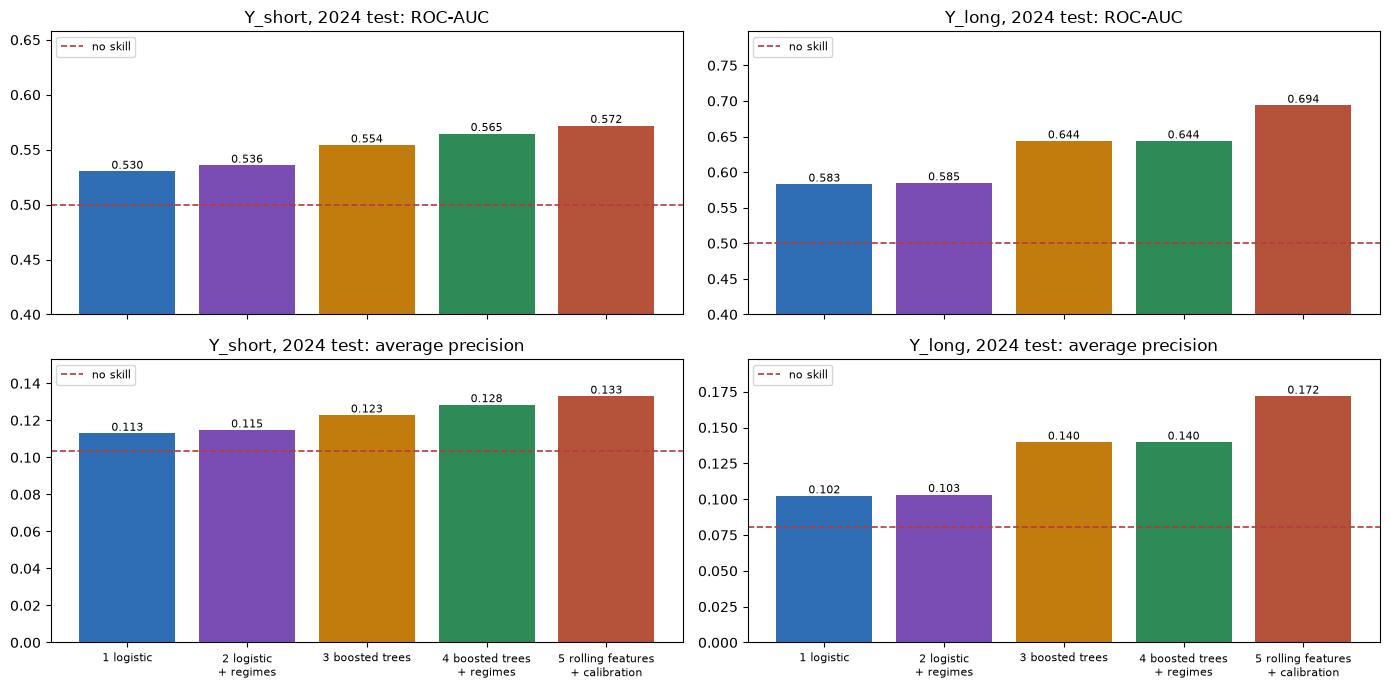

In [22]:

fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)
names = comparison["model"].unique()
for col, target in enumerate(["Y_short", "Y_long"]):
    sub = comparison[(comparison["target"] == target) & (comparison["split"] == "test")].set_index("model").loc[names]
    for row, (metric, ref, label) in enumerate([("roc_auc", 0.5, "ROC-AUC"), ("pr_auc", sub["base_rate"].iloc[0], "average precision")]):
        ax = axes[row, col]
        ax.bar(range(len(names)), sub[metric], color=["#2F6DB5", "#7A4DB5", "#C27C0E", "#2E8B57", "#B5523A"])
        ax.axhline(ref, color="#B53A3A", linestyle="--", linewidth=1.2, label="no skill")
        ax.set_title(f"{target}, 2024 test: {label}")
        ax.set_xticks(range(len(names)))
        ax.set_xticklabels([n.replace(" + ", "\n+ ") for n in names], fontsize=8)
        ax.set_ylim(0.4 if metric == "roc_auc" else 0, max(sub[metric].max(), ref) * 1.15)
        for i, v in enumerate(sub[metric]):
            ax.text(i, v, f"{v:.3f}", ha="center", va="bottom", fontsize=8)
        ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()


What the numbers say:

* **Model 5 has the best ranking in 2024 on both targets.** ROC-AUC is 0.572 (short) and 0.694 (long), average precision 0.133 and 0.172, against base rates of 0.104 and 0.080.
* **Models 1 to 4 rank the short side only a little better than chance.** ROC-AUC is about 0.60 in 2023 and 0.53 to 0.56 in 2024, against 0.5 for no skill. On the long side the logistic models reach about 0.58 and the boosted trees about 0.64.
* **The boosted trees of Models 3 and 4 are a clear step up from the logistic models, but only on the long side.** Their 2023 ROC-AUC on the long side is 0.69 against about 0.59, and their 2024 average precision is 0.140 against 0.102 and 0.103.
* **The regimes of Models 2 and 4 make little difference.** Adding them changes ROC-AUC by 0.01 or less in 2024 and never changes the long-side boosted-tree result.
* **All models fit 2021-22 much better than later years** (see the train rows above), which is what fixed 2021-22 thresholds and a very different price level in 2023 and 2024 would produce.
* **Probabilities are not better than a constant forecast in 2024, except for Model 5 on the long side.** The table of gains below is positive when a model beats the constant forecast. In 2023 every model beats it on both scores. In 2024 only Model 5 on the long side does (Brier score 0.0719 against 0.0743, log loss 0.268 against 0.282); on the short side it is level with the constant forecast on Brier score (0.0932 against 0.0929) and slightly worse on log loss.

In [23]:

gains = comparison[comparison["split"] != "train"].pivot_table(
    index=["target", "model"], columns="split", values=["brier_gain", "logloss_gain"])
gains.round(4)


brier_gain            logloss_gain  \
split                                          test validation         test   
target  model                                                                 
Y_long  1 logistic                          -0.0013     0.0025      -0.0154   
        2 logistic + regimes                -0.0013     0.0024      -0.0157   
        3 boosted trees                     -0.0016     0.0031      -0.0290   
        4 boosted trees + regimes           -0.0016     0.0031      -0.0290   
        5 rolling features + calibration     0.0024     0.0032       0.0140   
Y_short 1 logistic                          -0.0051     0.0010      -0.0625   
        2 logistic + regimes                -0.0051     0.0011      -0.0617   
        3 boosted trees                     -0.0041     0.0010      -0.0442   
        4 boosted trees + regimes           -0.0032     0.0011      -0.0307   
        5 rolling features + calibration    -0.0003     0.0014      -0.0032   

                                                     
split                                    validation  
target  model                                        
Y_long  1 logistic                           0.0168  
        2 logistic + regimes                 0.0166  
        3 boosted trees                      0.0237  
        4 boosted trees + regimes            0.0237  
        5 rolling features + calibration     0.0228  
Y_short 1 logistic                           0.0059  
        2 logistic + regimes                 0.0062  
        3 boosted trees                      0.0063  
        4 boosted trees + regimes            0.0076  
        5 rolling features + calibration     0.0091

#### How sure are the differences?

Each cell shows how much higher Model 5's score is than the score of the model named on that row, so a positive number means Model 5 is ahead. The range in brackets is a 95% interval from resampling the days of 2024 a thousand times. Whole days are resampled because stress comes in clusters within a day.

In [24]:
boot = pd.read_csv(ROOT / "results" / "model_5" / "bootstrap_differences.csv")
boot = boot[boot["model_5_minus"].isin(["Model 1", "Model 2", "Model 3", "Model 4"])]
boot["text"] = boot.apply(lambda r: f"{r.mean_diff:+.3f} [{r.ci_low:+.3f}, {r.ci_high:+.3f}]", axis=1)
table = boot.set_index(["target", "model_5_minus", "metric"])["text"].unstack("metric")[["ap", "roc"]]
table.index.names = ["target", "Model 5 compared with"]
table.columns = ["AP difference", "ROC-AUC difference"]
table.loc[["Y_short", "Y_long"]]


AP difference  \
target  Model 5 compared with                            
Y_short Model 1                +0.020 [+0.012, +0.029]   
        Model 2                +0.018 [+0.010, +0.027]   
        Model 3                +0.010 [-0.000, +0.021]   
        Model 4                +0.006 [-0.004, +0.017]   
Y_long  Model 1                +0.069 [+0.040, +0.105]   
        Model 2                +0.068 [+0.039, +0.104]   
        Model 3                +0.032 [+0.005, +0.059]   
        Model 4                +0.032 [+0.005, +0.059]   

                                    ROC-AUC difference  
target  Model 5 compared with                           
Y_short Model 1                +0.041 [+0.026, +0.057]  
        Model 2                +0.036 [+0.020, +0.052]  
        Model 3                +0.018 [-0.004, +0.039]  
        Model 4                +0.009 [-0.014, +0.031]  
Y_long  Model 1                +0.110 [+0.082, +0.140]  
        Model 2                +0.108 [+0.079, +0.138]  
        Model 3                +0.050 [+0.027, +0.075]  
        Model 4                +0.050 [+0.027, +0.075]

Reading the table:

* Against Models 1 and 2, Model 5 is ahead on both targets, and every interval stays above zero.
* Against Models 3 and 4, Model 5 is clearly ahead on the long side (AP +0.032, ROC-AUC +0.050). On the short side the intervals include zero, so the data cannot tell them apart.

### 6.7 Limitations

* **One test year.** All final results rest on 2024 alone. Severe events also come in clusters, so there are far fewer independent events than rows. Differences of a few thousandths in average precision between models should not be read as real.
* **The bootstrap intervals are too narrow.** They do not account for the uncertainty of fitting the models, nor for the number of comparisons made.
* **Fixed thresholds.** Keeping the 2021-22 cut-offs makes the share of severe intervals move between periods: about 10% in training, 7.2% and 5.3% in 2023, and 10.4% and 8.0% in 2024 for the short and long side. Price levels also differ a lot between the 2022 energy crisis and the later years.
* **Model 5 is not strictly like for like.** It is refitted on 2021-2023, so it has seen one more year than Models 1 to 4 before the 2024 test.
* **The binary target loses severity.** An interval 1 EUR/MWh above the cut-off and one 1,000 EUR/MWh above count the same.
* **Limited information.** Only day-ahead information is used. Intraday prices, outages and updated forecasts, which traders see before delivery, are left out. Offshore wind is also left out, because it is blank for the training years.
* **Data coverage.** Half-hours with missing day-ahead inputs or prices are dropped, and the balancing-price files change resolution many times, so the ex-post table has some blanks.

## 7. Conclusion

*Draft, to be adjusted.*

Information available after the day-ahead auction gives **some, but limited,** ability to flag severe imbalance-settlement stress in advance. The answer differs between the two sides.

* **Long positions: a usable signal.** The best model (Model 5) reaches a ROC-AUC of 0.69 in 2024, and its average precision of 0.17 is about twice the base rate of 0.08. Severe long-side stress follows the fundamentals that drive surpluses: the day-ahead price, the load forecast and the solar forecast. A participant could use the model to rank the next day's half-hours and focus hedging or intraday re-trading on the riskiest ones.
* **Short positions: barely better than chance.** The best 2024 ROC-AUC is 0.57, with an average precision of 0.13 against a base rate of 0.10. Severe short-side stress seems to come mostly from events after the auction (outages, forecast errors, intraday moves) that day-ahead data cannot see.
* **What helped.** Non-linear models (boosted trees) improve on logistic regression on the long side. Recent stress history and price levels relative to recent weeks (Model 5) help further. The hidden-Markov regimes add almost nothing beyond what the day-ahead inputs and the time of day already capture.
* **Probabilities.** The predicted probabilities are not reliably better than a constant forecast, except for the calibrated Model 5 on the long side. The models are more useful for **ranking** half-hours than as exact probabilities.

Overall, day-ahead fundamentals can help screen for long-side stress but cannot predict short-side stress well. Natural next steps are adding intraday and outage information, testing on more years (for example 2025), and modelling how large the stress is, not just whether it is severe.